     WORD EMBEDDINGS SYSTEM
Loading embedding model...


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1986.97it/s]


Model loaded successfully!


Batches: 100%|██████████| 1/1 [00:00<00:00, 37.16it/s]

Embedding shape: (10, 384)

========== EMBEDDING VECTORS ==========

Word: king
Dimensions: 384
First 10 values: [-0.0596  0.0505 -0.0695  0.0797 -0.0467  0.001   0.079  -0.0127  0.0584
 -0.0314]

Word: queen
Dimensions: 384
First 10 values: [ 0.0355 -0.0656 -0.0099  0.0316 -0.0134  0.0289  0.1167 -0.0343  0.0544
 -0.0056]

Word: man
Dimensions: 384
First 10 values: [-0.1097  0.0437 -0.0263 -0.0293  0.0216 -0.0855  0.1137 -0.0682 -0.011
 -0.0466]

Word: woman
Dimensions: 384
First 10 values: [-0.0456  0.0113 -0.0191  0.0444 -0.0469  0.0277  0.1134 -0.006   0.0318
 -0.0063]

Word: apple
Dimensions: 384
First 10 values: [-0.0061  0.031   0.0648  0.0109  0.0053 -0.0475  0.0812  0.029   0.0668
  0.0303]

Word: banana
Dimensions: 384
First 10 values: [-5.430e-02  1.400e-02 -2.480e-02  2.690e-02 -1.000e-04  3.390e-02
  1.033e-01  5.130e-02  2.070e-02  5.110e-02]

Word: car
Dimensions: 384
First 10 values: [-0.0333  0.1058  0.0189  0.0519 -0.0375  0.0312  0.1226  0.0424  0.0419
 -0.047 ]

Wor

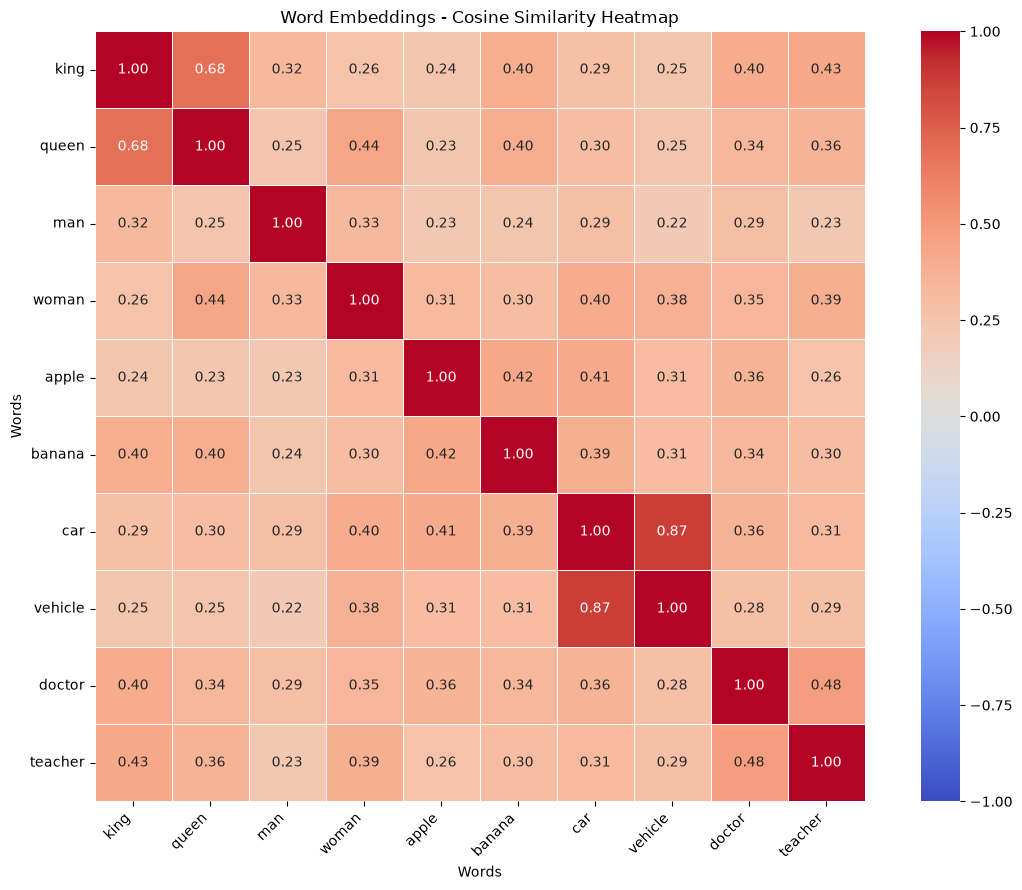


========== PCA VISUALIZATION ==========


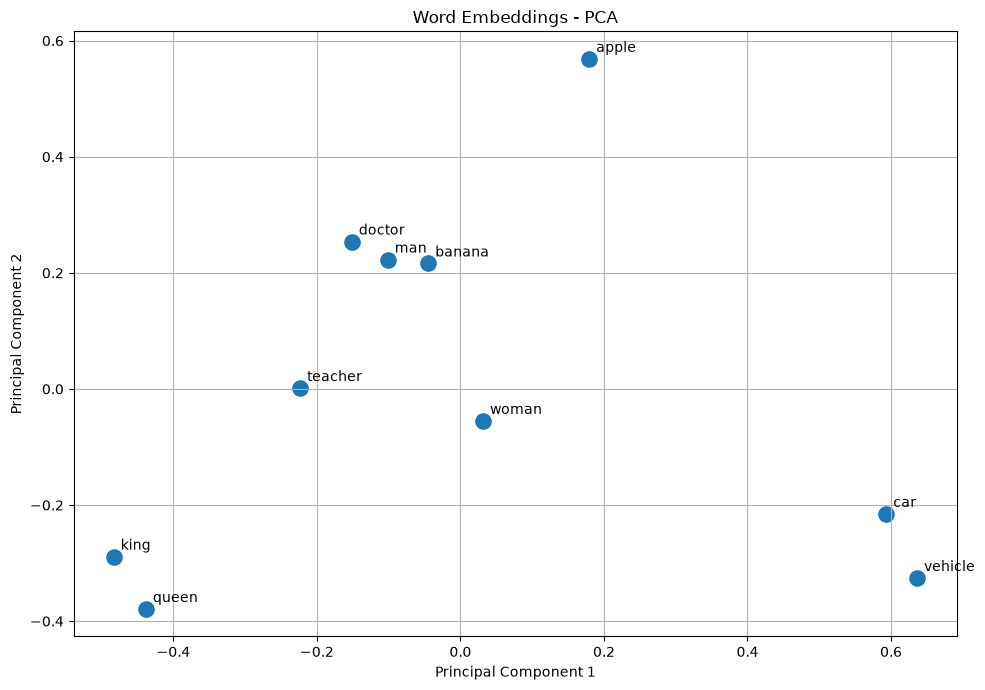


========== SEMANTIC SEARCH ==========


Batches: 100%|██████████| 1/1 [00:00<00:00, 108.91it/s]

Embedding shape: (1, 384)

Query: royalty

Search Results:
queen           Similarity: 0.6522
king            Similarity: 0.6323
teacher         Similarity: 0.4134
doctor          Similarity: 0.3558
woman           Similarity: 0.3372
banana          Similarity: 0.3220
car             Similarity: 0.2962
man             Similarity: 0.2222
vehicle         Similarity: 0.2170
apple           Similarity: 0.2039

       PROGRAM COMPLETED


In [23]:

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA


# ==========================================
# 1. WORD EMBEDDINGS CLASS
# ==========================================

class WordEmbeddings:

    def __init__(self):

        print("Loading embedding model...")

        self.model = SentenceTransformer(
            "all-MiniLM-L6-v2"
        )

        print("Model loaded successfully!")

    # ENCODER
    def encoder(self, words):

        vectors = self.model.encode(
            words,
            show_progress_bar=True
        )

        print("Embedding shape:", vectors.shape)

        return vectors

    # DISPLAY EMBEDDINGS
    def show_embeddings(self, words, vectors):

        print("\n========== EMBEDDING VECTORS ==========")

        for word, vector in zip(words, vectors):

            print(f"\nWord: {word}")
            print("Dimensions:", len(vector))
            print("First 10 values:", np.round(vector[:10], 4))

    # COSINE SIMILARITY + HEATMAP
    def similarity(self, words, vectors):

        print("\n========== COSINE SIMILARITY ==========")

        matrix = cosine_similarity(vectors)

        print(np.round(matrix, 3))

        plt.figure(figsize=(12, 9))

        sns.heatmap(
            matrix,
            annot=True,
            fmt=".2f",
            cmap="coolwarm",
            xticklabels=words,
            yticklabels=words,
            linewidths=0.5,
            vmin=-1,
            vmax=1,
            square=True
        )

        plt.title("Word Embeddings - Cosine Similarity Heatmap")
        plt.xlabel("Words")
        plt.ylabel("Words")

        plt.xticks(rotation=45, ha="right")
        plt.yticks(rotation=0)

        plt.tight_layout()
        plt.show()

        return matrix

    # PCA VISUALIZATION
    def visualize(self, words, vectors):

        print("\n========== PCA VISUALIZATION ==========")

        pca = PCA(n_components=2)

        reduced = pca.fit_transform(vectors)

        plt.figure(figsize=(10, 7))

        plt.scatter(
            reduced[:, 0],
            reduced[:, 1],
            s=120
        )

        for i, word in enumerate(words):

            plt.annotate(
                word,
                (reduced[i, 0], reduced[i, 1]),
                xytext=(5, 5),
                textcoords="offset points"
            )

        plt.title("Word Embeddings - PCA")
        plt.xlabel("Principal Component 1")
        plt.ylabel("Principal Component 2")

        plt.grid(True)
        plt.tight_layout()
        plt.show()

    # SEMANTIC SEARCH
    def search(self, query, words, vectors):

        print("\n========== SEMANTIC SEARCH ==========")

        query_vector = self.encoder([query])

        scores = cosine_similarity(
            query_vector,
            vectors
        )[0]

        results = sorted(
            zip(words, scores),
            key=lambda x: x[1],
            reverse=True
        )

        print("\nQuery:", query)
        print("\nSearch Results:")

        for word, score in results:

            print(f"{word:<15} Similarity: {score:.4f}")


# ==========================================
# 2. MAIN PROGRAM
# ==========================================

words = [
    "king",
    "queen",
    "man",
    "woman",
    "apple",
    "banana",
    "car",
    "vehicle",
    "doctor",
    "teacher"
]

print("================================")
print("     WORD EMBEDDINGS SYSTEM")
print("================================")

# Create object
embedding = WordEmbeddings()

# Generate embeddings
vectors = embedding.encoder(words)

# Display vectors
embedding.show_embeddings(words, vectors)

# Similarity matrix + HEATMAP
matrix = embedding.similarity(words, vectors)

# PCA visualization
embedding.visualize(words, vectors)

# Semantic search
embedding.search(
    "royalty",
    words,
    vectors
)

print("\n================================")
print("       PROGRAM COMPLETED")
print("================================")
